# 27 · Safer recommendations (work package 16)

**Work package 16** of the [applications plan](../../research/implementation_plan_applications.md), section 16.
How often does the recommender list tokens that collapse soon after, and what does listing fewer of them cost?

- **Harm:** for the frozen fixed blend's top-10 lists at the Dev B and test points: the share of list entries
  whose token collapses within 72 hours (WP13's label), and the share of hits (listed, then picked up) on such tokens.
- **Re-ranking:** the blend's first 50 tokens per account re-ordered by score − λ × risk, with the risk from the
  WP13 baseline model (`project_direction.md`, 24 November); λ ∈ {0, 0.1, 0.2, 0.5, 1, 2}.
- **Choice of λ on Dev B:** the largest fall in the collapsed share whose loss of recall is at most 5% of the
  unchanged recall.
- **Criterion (stated in the plan):** on the test, with that λ, the collapsed share falls (paired over points,
  95% interval excluding zero) and recall falls by at most 5% of its value. The whole curve is reported either way.

Built by `src/scripts/build_safer.py` (results/wp16/).

In [1]:
import sys

sys.path.append("../scripts")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

import plots
import protocol as pc
import stats

plots.style()
pd.set_option("display.float_format", "{:,.4f}".format)
tradeoff = pd.read_csv(pc.RESULTS_DIR / "wp16" / "tradeoff.csv", parse_dates=["point"])
listed = pd.read_parquet(pc.RESULTS_DIR / "wp16" / "list_tokens.parquet")
listed.groupby("part").agg(points=("point", "nunique"), tokens_per_point=("token", lambda s: len(s) / listed.loc[s.index, "point"].nunique()),
                           collapse_rate=("collapsed", "mean"), collapsed_tokens=("collapsed", "sum"))  # fmt: skip

,points,tokens_per_point,collapse_rate,collapsed_tokens
part,,,,
dev_b,11,"4,258.0909",0.6159,28848
test,14,"4,915.5714",0.6412,44123


The rows above are all tokens on the candidate lists (first 50 per account). How well does the risk score rank
them (AUC for collapse)?

In [2]:
listed.groupby("part").apply(lambda p: roc_auc_score(p["collapsed"], p["risk"]) if p["collapsed"].nunique() == 2 else np.nan, include_groups=False).rename("AUC of the risk score")

part
dev_b   0.9134
test    0.9132
Name: AUC of the risk score, dtype: float64

## 1. The harm of the frozen lists (λ = 0)

In [3]:
frozen = tradeoff[tradeoff["lam"] == 0]
frozen.groupby("part")[["recall", "collapsed_share", "harmful_hit_share", "accounts_with_a_collapsing_token"]].agg(["mean", "max"])

recall        collapsed_share        harmful_hit_share         \
        mean    max            mean    max              mean    max   
part                                                                  
dev_b 0.1422 0.1561          0.0561 0.0950            0.0058 0.0207   
test  0.1529 0.1960          0.0601 0.0915            0.0072 0.0374   

      accounts_with_a_collapsing_token         
                                  mean    max  
part                                           
dev_b                           0.1972 0.2886  
test                            0.1712 0.2820

## 2. The trade-off curve

Means over points of recall and of the collapsed share, per λ.

In [4]:
curve = tradeoff.groupby(["part", "lam"])[["recall", "collapsed_share", "harmful_hit_share"]].mean()
base = curve.xs(0, level="lam")
curve["recall_loss_relative"] = 1 - curve["recall"] / base["recall"].reindex(curve.index.get_level_values("part")).to_numpy()
curve["collapsed_fall_relative"] = 1 - curve["collapsed_share"] / base["collapsed_share"].reindex(curve.index.get_level_values("part")).to_numpy()
curve

recall  collapsed_share  harmful_hit_share  \
part  lam                                                  
dev_b 0.0000  0.1422           0.0561             0.0058   
      0.1000  0.1418           0.0529             0.0055   
      0.2000  0.1413           0.0506             0.0051   
      0.5000  0.1411           0.0448             0.0047   
      1.0000  0.1405           0.0367             0.0041   
      2.0000  0.1398           0.0289             0.0030   
test  0.0000  0.1529           0.0601             0.0072   
      0.1000  0.1521           0.0578             0.0067   
      0.2000  0.1517           0.0562             0.0059   
      0.5000  0.1505           0.0508             0.0050   
      1.0000  0.1501           0.0429             0.0042   
      2.0000  0.1498           0.0326             0.0038   

              recall_loss_relative  collapsed_fall_relative  
part  lam                                                    
dev_b 0.0000                0.0000                   0.0000  
      0.1000                0.0032                   0.0571  
      0.2000                0.0063                   0.0972  
      0.5000                0.0080                   0.2010  
      1.0000                0.0122                   0.3463  
      2.0000                0.0175                   0.4852  
test  0.0000                0.0000                   0.0000  
      0.1000                0.0047                   0.0381  
      0.2000                0.0077                   0.0639  
      0.5000                0.0154                   0.1545  
      1.0000                0.0178                   0.2865  
      2.0000                0.0200                   0.4575

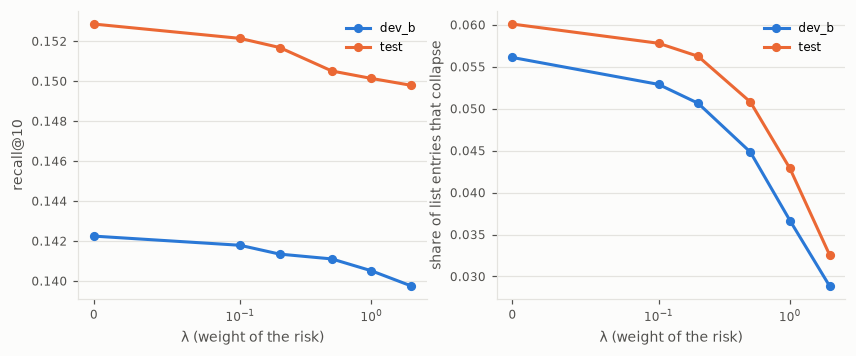

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
for slot, part in enumerate(["dev_b", "test"]):
    part_curve = curve.xs(part, level="part")
    axes[0].plot(part_curve.index, part_curve["recall"], marker="o", color=plots.SERIES[slot], label=part)
    axes[1].plot(part_curve.index, part_curve["collapsed_share"], marker="o", color=plots.SERIES[slot], label=part)
for ax, label in zip(axes, ["recall@10", "share of list entries that collapse"]):
    ax.set_xscale("symlog", linthresh=0.1)
    ax.set_xlabel("λ (weight of the risk)")
    ax.set_ylabel(label)
    ax.legend()
plt.show()

## 3. Choosing λ on Dev B

In [6]:
dev_b = curve.xs("dev_b", level="part")
allowed = dev_b[(dev_b["recall_loss_relative"] <= 0.05) & (dev_b.index > 0)]
LAM = float(allowed["collapsed_fall_relative"].idxmax()) if len(allowed) and allowed["collapsed_fall_relative"].max() > 0 else 0.0
print(f"Chosen λ = {LAM}" + ("" if LAM else " (no λ > 0 lowers the collapsed share within the recall limit)"))

Chosen λ = 2.0


## 4. The criterion on the test

In [7]:
test = tradeoff[tradeoff["part"] == "test"]
if LAM > 0:
    chosen, unchanged = test[test["lam"] == LAM].set_index("point"), test[test["lam"] == 0].set_index("point")
    d = chosen["collapsed_share"] - unchanged["collapsed_share"]
    low, high = stats.bootstrap_over_points(d)
    loss = 1 - chosen["recall"].mean() / unchanged["recall"].mean()
    met = d.mean() < 0 and high < 0 and loss <= 0.05
    print(f"Collapsed share: {unchanged['collapsed_share'].mean():.4f} -> {chosen['collapsed_share'].mean():.4f}, difference {d.mean():+.4f} "
          f"[{low:+.4f}, {high:+.4f}], lower at {(d < 0).sum()} of {len(d)} points")  # fmt: skip
    print(f"Recall: {unchanged['recall'].mean():.4f} -> {chosen['recall'].mean():.4f} (loss {loss:.1%} of its value)")
    print(f"Criterion: {'MET' if met else 'NOT met'}")
else:
    print("No λ was chosen on Dev B; the criterion cannot be met. The test curve is shown above.")

Collapsed share: 0.0601 -> 0.0326, difference -0.0275 [-0.0326, -0.0219], lower at 14 of 14 points
Recall: 0.1529 -> 0.1498 (loss 2.0% of its value)
Criterion: MET


## 5. What kind of collapse?

WP13's label has two ways to collapse: a price fall of more than 90% with trading stopping, or no real priced
swap left while trading stops (a dead token). At the last test point, the share of collapsing listed tokens that
still had a priced swap of at least 0.01 ETH in the 72 hours (the only ones that can show a price fall):

In [8]:
import build_scam_push as bsp
import token_data as td

address = td.load_tokens().set_index("token_id")["address"]
t_last = listed["point"].max()
collapsed_last = listed[(listed["point"] == t_last) & listed["collapsed"]].assign(address=lambda f: f["token"].map(address))
priced = bsp.token_swaps(set(collapsed_last["address"]), t_last, t_last + pd.Timedelta(hours=72))
priced = priced[priced["volume_eth"] >= 0.01]
print(f"{t_last:%d %b}: {len(collapsed_last):,} collapsing listed tokens; with a real priced swap in the 72 hours: "
      f"{collapsed_last['address'].isin(set(priced['token'])).mean():.1%}; their median trades in the last 24 hours: "
      f"{collapsed_last['late_trades'].median():.0f}; median accounts ever: {collapsed_last['accounts_before'].median():.0f} "
      f"(tokens that do not collapse: {listed.loc[~listed['collapsed'], 'accounts_before'].median():.0f})")  # fmt: skip

08 Sep: 3,438 collapsing listed tokens; with a real priced swap in the 72 hours: 0.0%; their median trades in the last 24 hours: 0; median accounts ever: 11 (tokens that do not collapse: 145)


## 6. What this shows

- **The criterion is met.** With λ = 2, chosen on Dev B, the share of list entries whose token collapses within
  72 hours falls on the test from 6.0% to 3.3% (−0.028, interval −0.033 to −0.022, lower at all 14 points), and
  recall@10 falls from 0.153 to 0.150, a loss of 2.0% of its value (the limit was 5%). Harmful hits (hits on
  collapsing tokens) fall from 0.72% to 0.38% of hits.
- **The "collapses" are dead tokens, not crashes.** At the last test point every collapsing listed token had no
  priced swap of at least 0.01 ETH in the 72 hours after the point and almost no trades at all; they are tokens
  with few accounts ever (median 11, against 145 for the others) that the neighbour part of the blend lists because
  an account's co-traders once touched them. So the result reads: **about 6% of what the frozen recommender lists
  is a token nobody will trade again, and a risk score from age and activity halves that at a 2% cost in recall.**
  Price crashes of tokens on the lists are too rare to measure here.
- **The risk score works well on listed tokens** (AUC 0.91 for collapse on both parts), which is why the
  re-ranking can remove dead tokens without losing hits: the tokens it pushes down are rarely picked up anyway.
- **λ = 2 is the largest value tried**, so a stronger penalty might remove more dead tokens within the 5% limit;
  the grid was fixed in the plan and is not extended after seeing the test.
- **Accounts affected:** 17-20% of evaluated accounts get at least one collapsing token on their unchanged list.